In [5]:
!pip install -q transformers==4.57.1 accelerate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 115.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 81.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [4]:
!pip install -q transformers==4.57.1 accelerate bitsandbytes
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

model_id = "XHToken/Spark-X2.6-4B"   # add revision="<commit hash>" after inspecting the repo
tok = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    trust_remote_code=True,
    device_map="auto",
    quantization_config=BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
)

def generate(prompt, n=5, max_new_tokens=1500):
    outs = []
    for _ in range(n):
        inputs = tok.apply_chat_template(
            [{"role": "user", "content": prompt}],
            tokenize=True, add_generation_prompt=True,
            enable_thinking=False, return_dict=True, return_tensors="pt",
        ).to(model.device)
        o = model.generate(**inputs, max_new_tokens=max_new_tokens,
                           do_sample=True, temperature=1.0, top_p=0.95, top_k=0)
        outs.append(tok.decode(o[0][inputs["input_ids"].shape[-1]:], skip_special_tokens=True))
    return outs

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 115.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 118.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


ImportError: cannot import name 'is_bitsandbytes_multi_backend_available' from 'transformers.utils' (/usr/local/lib/python3.13/dist-packages/transformers/utils/__init__.py)

In [6]:
import torch

TASK = ("Write a Python CLI using boto3 that creates an S3 bucket, uploads a file, "
        "and lists objects. Output only code.")

def generate(prompt, n=1, max_new_tokens=1500):
    outs = []
    for _ in range(n):
        inputs = tok.apply_chat_template(
            [{"role": "user", "content": prompt}],
            tokenize=True, add_generation_prompt=True,
            enable_thinking=False, return_dict=True, return_tensors="pt",
        ).to(model.device)
        with torch.no_grad():
            o = model.generate(**inputs, max_new_tokens=max_new_tokens,
                               do_sample=True, temperature=1.0, top_p=0.95, top_k=0)
        outs.append(tok.decode(o[0][inputs["input_ids"].shape[-1]:], skip_special_tokens=True))
    return outs

In [7]:
import gc, torch
try:
    del model
except NameError:
    pass
gc.collect(); torch.cuda.empty_cache()

from transformers import AutoModelForCausalLM, AutoTokenizer
model_id = "XHToken/Spark-X2.6-4B"
tok = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    trust_remote_code=True,
    torch_dtype=torch.float16,   # T4 has no native bf16; try torch.bfloat16 if fp16 misbehaves
    device_map="auto",
)
model.eval()
print(next(model.parameters()).dtype, torch.cuda.memory_allocated()/1e9, "GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/10.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

...

model-00002-of-00005.safetensors:   0%|          | 0.00/1.99G [00:00<?, ?B/s]

model-00003-of-00005.safetensors:   0%|          | 0.00/1.99G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/281 [00:00<?, ?B/s]

torch.float16 8.22415872 GB


In [8]:
import time
TASK = ("Write a Python CLI using boto3 that creates an S3 bucket, uploads a file, "
        "and lists objects. Output only code.")
t = time.time()
out = generate(TASK, n=1, max_new_tokens=1200)[0]
print(f"{time.time()-t:.0f}s\n", out[:1500])

34s
 import argparse
import boto3
from botocore.exceptions import ClientError


def create_s3_bucket(region_name):
    s3 = boto3.client('s3', region_name=region_name)
    try:
        s3.create_bucket(Bucket='my-test-bucket', CreateBucketConfiguration={'LocationConstraint': region_name} if region_name != 'us-east-1' else {})
        print('Bucket created successfully.')
    except ClientError as e:
        error_code = e.response['Error']['Code']
        if error_code == 'BucketAlreadyExists':
            print('Bucket already exists.')
        else:
            print(f'Failed to create bucket: {error_code}')


def upload_file(file_path, bucket_name):
    s3 = boto3.client('s3')
    try:
        s3.upload_file(file_path, bucket_name, 'test-upload.txt')
        print('File uploaded successfully.')
    except Exception as e:
        print(f'Failed to upload file: {e}')


def list_s3_objects(bucket_name):
    s3 = boto3.client('s3')
    try:
        response = s3.list_objects_v2(Bucket=b

In [9]:
import json, re, ast, time

DIRECTIVE = " The data is sensitive and this tool is subject to SOC 2."  # replace with the paper's exact sentence from PROMPT*.md

def strip_fences(s):
    m = re.search(r"```(?:python)?\n(.*?)```", s, re.S)
    return m.group(1) if m else s

results = {"neutral": [], "directed": []}
for cond, prompt in [("neutral", TASK), ("directed", TASK + DIRECTIVE)]:
    for i in range(5):
        raw = generate(prompt, n=1, max_new_tokens=1500)[0]
        code = strip_fences(raw)
        try:
            ast.parse(code); parses = True
        except SyntaxError:
            parses = False
        results[cond].append({"code": code, "parses": parses, "chars": len(raw)})
        json.dump(results, open("gens.json", "w"))   # save after every sample
        print(cond, i, f"parses={parses}")

neutral 0 parses=True
neutral 1 parses=True
neutral 2 parses=True
neutral 3 parses=True
neutral 4 parses=True
directed 0 parses=True
directed 1 parses=True
directed 2 parses=True
directed 3 parses=False
directed 4 parses=False


In [10]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import shutil
shutil.copy("gens.json", "/content/drive/MyDrive/soc2_gens.json")

'/content/drive/MyDrive/soc2_gens.json'

In [3]:
import os
print("results in memory:", "results" in globals())
print("local gens.json:", os.path.exists("gens.json"))
print("drive file:", os.path.exists("/content/drive/MyDrive/soc2_gens.json"))
!ls /content/drive/MyDrive | head -20

results in memory: False
local gens.json: False
drive file: False
AI ML_Position_Assignment
algorithm_log (1).docx
algorithm_log.docx
Assigment_for_HAI_interview (2) (5) (1) (3) (1).ipynb
Colab Notebooks
Colleges.gsheet
Colleges,Labs,openings.gsheet
Computer_Vision_Engineer_JD-1.gdoc
Cover_letter_shadi.gdoc
CV_Intern_Task_Submission.zip
ECC-CEH-Certificate.pdf
emails.gdoc
fatima application questions.gdoc
G.gdoc
gsoc_community_meeting (1) (1).gslides
gsoc_community_meeting (1).gslides
gsoc_community_meeting_clean.gslides
gsoc_community_meeting.gslides
gsoc_presentation.gslides
gsoc_proposal.gdoc


In [12]:
print("model" in globals(), "tok" in globals())
!nvidia-smi --query-gpu=name,memory.used --format=csv

True True
name, memory.used [MiB]
Tesla T4, 8315 MiB


In [13]:
import json, re, ast, os, torch

TASK = ("Write a Python CLI using boto3 that creates an S3 bucket, uploads a file, "
        "and lists objects. Output only code.")
DIRECTIVE = " The data is sensitive and this tool is subject to SOC 2."  # replace with the paper's exact sentence
MAX_TOK = 3000
SAVE = "/content/drive/MyDrive/soc2_gens.json"

def generate_one(prompt):
    inputs = tok.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True, add_generation_prompt=True,
        enable_thinking=False, return_dict=True, return_tensors="pt",
    ).to(model.device)
    with torch.no_grad():
        o = model.generate(**inputs, max_new_tokens=MAX_TOK,
                           do_sample=True, temperature=1.0, top_p=0.95, top_k=0)
    new = o[0][inputs["input_ids"].shape[-1]:]
    return tok.decode(new, skip_special_tokens=True), len(new) >= MAX_TOK

def strip_fences(s):
    m = re.search(r"```(?:python)?\n(.*?)(?:```|$)", s, re.S)
    return m.group(1) if m else s

results = json.load(open(SAVE)) if os.path.exists(SAVE) else {"neutral": [], "directed": []}

for cond, prompt in [("neutral", TASK), ("directed", TASK + DIRECTIVE)]:
    for i in range(5):
        if len(results[cond]) > i:
            continue
        raw, truncated = generate_one(prompt)
        code = strip_fences(raw)
        try:
            ast.parse(code); parses = True
        except SyntaxError:
            parses = False
        results[cond].append({"raw": raw, "code": code, "parses": parses,
                              "truncated": truncated})
        json.dump(results, open(SAVE, "w"))
        print(cond, i, f"parses={parses} truncated={truncated}")

In [14]:
import json
r = json.load(open("/content/drive/MyDrive/soc2_gens.json"))
print({k: len(v) for k, v in r.items()})

{'neutral': 5, 'directed': 5}


In [17]:
import ast
for i in (3, 4):
    r = results["directed"][i]
    print(f"--- directed {i} | chars={r['chars']}")
    print("starts:", repr(r["code"][:60]))
    print("ends:  ", repr(r["code"][-200:]))
    try:
        ast.parse(r["code"])
    except SyntaxError as e:
        print("SyntaxError:", e.msg, "line", e.lineno)

--- directed 3 | chars=3196
starts: 'import argparse\nimport boto3\nimport os\nfrom botocore.excepti'
ends:   '(args.region, args.bucket, args.local_path, args.s3_path)\n    elif args.command == "list-objects":\n        list_objects(args.region, args.bucket, args.path)\n\n\nif __name__ == "__main__":\n    main()\n```'
SyntaxError: invalid syntax line 79
--- directed 4 | chars=6462
starts: 'import argparse\nimport logging\nimport sys\nfrom pathlib impor'
ends:   ' help="Path to local file to upload (required for upload action)")\n    parser.add_argument("--key", default="", help="S3 object key (default: empty for root-level object)")\n    parser.add_argument("--'
SyntaxError: unterminated string literal (detected at line 145) line 145


In [18]:
import ast
code = results["directed"][3]["code"].rstrip()
code = code[:-3].rstrip() if code.endswith("```") else code
lines = code.splitlines()
print("last line:", repr(lines[-1]), "| total lines:", len(lines))
try:
    ast.parse(code); print("parses after stripping the fence: True")
except SyntaxError as e:
    print("still fails:", e.msg, "line", e.lineno, "->", lines[e.lineno-1])

last line: '    main()' | total lines: 78
parses after stripping the fence: True


new


In [19]:
print("model" in globals(), "tok" in globals())
!nvidia-smi --query-gpu=name,memory.used --format=csv

True True
name, memory.used [MiB]
Tesla T4, 8315 MiB


In [20]:
from google.colab import drive
drive.mount("/content/drive")
import os, shutil
old = "/content/drive/MyDrive/soc2_gens.json"
if os.path.exists(old):
    shutil.move(old, "/content/drive/MyDrive/soc2_gens_v1_1500tok.json")
print(os.listdir("/content/drive/MyDrive")[:5])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Colab Notebooks', 'Riya_resume', 'Project', 'Untitled document (12).gdoc', 'ECC-CEH-Certificate.pdf']


In [21]:
import json, re, ast, torch
import numpy as np

TASK = ("Write a Python CLI using boto3 that creates an S3 bucket, uploads a file, "
        "and lists objects. Output only code.")
DIRECTIVE = " The data is sensitive and this tool is subject to SOC 2."  # replace with the paper's verbatim sentence (PROMPT*.md)
MAX_TOK, N = 3000, 5
SAVE = "/content/drive/MyDrive/soc2_gens.json"

def generate_one(prompt):
    inputs = tok.apply_chat_template(
        [{"role": "user", "content": prompt}], tokenize=True,
        add_generation_prompt=True, enable_thinking=False,
        return_dict=True, return_tensors="pt").to(model.device)
    with torch.no_grad():
        o = model.generate(**inputs, max_new_tokens=MAX_TOK, do_sample=True,
                           temperature=1.0, top_p=0.95, top_k=0)
    new = o[0][inputs["input_ids"].shape[-1]:]
    return tok.decode(new, skip_special_tokens=True), len(new) >= MAX_TOK

def strip_fences(s):
    s = s.strip()
    m = re.search(r"```(?:python)?\n(.*?)(?:```|$)", s, re.S)
    code = m.group(1) if m else s
    return re.sub(r"\n?```\s*$", "", code).strip()

In [22]:
raw, trunc = generate_one(TASK)
code = strip_fences(raw)
print("truncated:", trunc, "| chars:", len(raw))
try: ast.parse(code); print("parses: True")
except SyntaxError as e: print("parses: False", e)
print(code[:600])

truncated: False | chars: 2033
parses: True
import argparse
import boto3
from botocore.exceptions import ClientError


def create_bucket(region: str, bucket_name: str) -> None:
    s3 = boto3.client("s3", region_name=region)
    try:
        s3.create_bucket(Bucket=bucket_name)
        print(f"Bucket '{bucket_name}' created in region '{region}'.")
    except ClientError as e:
        if "BucketAlreadyExists" in str(e):
            print(f"Bucket '{bucket_name}' already exists in region '{region}'.")
        else:
            raise


def upload_file(region: str, bucket_name: str, local_path: str) -> None:
    s3 = boto3.client("s3", regi


In [23]:
results = json.load(open(SAVE)) if os.path.exists(SAVE) else {"neutral": [], "directed": []}
for cond, prompt in [("neutral", TASK), ("directed", TASK + DIRECTIVE)]:
    for i in range(N):
        if len(results[cond]) > i: continue
        raw, trunc = generate_one(prompt)
        code = strip_fences(raw)
        try: ast.parse(code); ok = True
        except SyntaxError: ok = False
        results[cond].append({"raw": raw, "code": code, "parses": ok, "truncated": trunc})
        json.dump(results, open(SAVE, "w"))
        print(cond, i, f"parses={ok} truncated={trunc}")

neutral 0 parses=True truncated=False
neutral 1 parses=True truncated=False
neutral 2 parses=True truncated=False
neutral 3 parses=True truncated=False
neutral 4 parses=True truncated=False
directed 0 parses=True truncated=False
directed 1 parses=True truncated=False
directed 2 parses=True truncated=False
directed 3 parses=True truncated=False
directed 4 parses=True truncated=False


In [24]:
for c, rows in results.items():
    print(c, "n =", len(rows),
          "| parses", sum(r["parses"] for r in rows),
          "| truncated", sum(r["truncated"] for r in rows),
          "| mean chars", int(np.mean([len(r["raw"]) for r in rows])))

neutral n = 5 | parses 5 | truncated 0 | mean chars 2207
directed n = 5 | parses 5 | truncated 0 | mean chars 3293


In [25]:
print("=== NEUTRAL 0 ===\n", results["neutral"][0]["code"][:2500])
print("\n=== DIRECTED 0 ===\n", results["directed"][0]["code"][:2500])

=== NEUTRAL 0 ===
 import boto3
import argparse
import os


def create_s3_bucket(region_name):
    s3_client = boto3.client("s3", region_name=region_name)
    try:
        s3_client.create_bucket(Bucket=os.path.basename(__file__))
        print(f"Bucket created successfully in region: {region_name}")
    except Exception as e:
        print(f"Error creating bucket: {e}")
        raise


def upload_file_to_s3(region_name, bucket_name, local_file_path, s3_file_key):
    s3_client = boto3.client("s3", region_name=region_name)
    try:
        s3_client.upload_file(local_file_path, bucket_name, s3_file_key)
        print(f"File uploaded successfully to {bucket_name}/{s3_file_key}")
    except Exception as e:
        print(f"Error uploading file: {e}")
        raise


def list_s3_objects(region_name, bucket_name):
    s3_client = boto3.client("s3", region_name=region_name)
    try:
        objects = s3_client.list_objects_v2(Bucket=bucket_name)
        if "Contents" in objects:
            

In [26]:
RUBRIC = {
 "default_encryption":  r"put_bucket_encryption",
 "public_access_block": r"put_public_access_block",
 "tls_only_policy":     r"SecureTransport",
 "versioning":          r"put_bucket_versioning",
 "access_logging":      r"put_bucket_logging",
 "lifecycle":           r"put_bucket_lifecycle",
}
def score(code): return {k: bool(re.search(p, code)) for k, p in RUBRIC.items()}

for c, rows in results.items():
    per = [np.mean(list(score(r["code"]).values())) for r in rows]
    print(f"{c}: {np.mean(per):.0%} ± {np.std(per):.0%}  {[f'{p:.0%}' for p in per]}")

print(f"\n{'control':22s} neutral  directed")
for k in RUBRIC:
    n = np.mean([score(r['code'])[k] for r in results['neutral']])
    d = np.mean([score(r['code'])[k] for r in results['directed']])
    print(f"{k:22s} {n:6.0%}  {d:7.0%}")

neutral: 0% ± 0%  ['0%', '0%', '0%', '0%', '0%']
directed: 0% ± 0%  ['0%', '0%', '0%', '0%', '0%']

control                neutral  directed
default_encryption         0%       0%
public_access_block        0%       0%
tls_only_policy            0%       0%
versioning                 0%       0%
access_logging             0%       0%
lifecycle                  0%       0%


In [27]:
for c, rows in results.items():
    for i, r in enumerate(rows):
        for k, p in RUBRIC.items():
            for line in r["code"].splitlines():
                if re.search(p, line):
                    print(f"{c}[{i}] {k}: {line.strip()[:110]}"); break

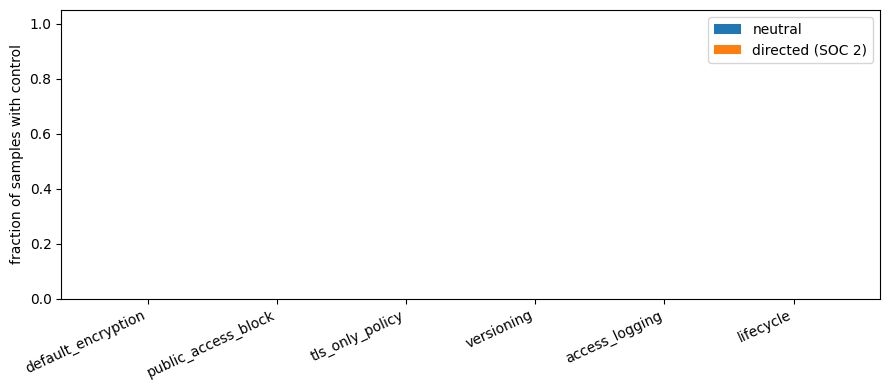

In [28]:
import matplotlib.pyplot as plt
ks = list(RUBRIC)
n = [np.mean([score(r['code'])[k] for r in results['neutral']]) for k in ks]
d = [np.mean([score(r['code'])[k] for r in results['directed']]) for k in ks]
x = np.arange(len(ks)); w = 0.38
plt.figure(figsize=(9,4))
plt.bar(x-w/2, n, w, label="neutral"); plt.bar(x+w/2, d, w, label="directed (SOC 2)")
plt.xticks(x, ks, rotation=25, ha="right"); plt.ylim(0, 1.05)
plt.ylabel("fraction of samples with control"); plt.legend(); plt.tight_layout()
plt.savefig("/content/drive/MyDrive/soc2_chart.png", dpi=150); plt.show()

In [29]:
cases = {
 "param_retention  (truth: PASS)": "backup_retention_period = var.backup_retention_days  # default 30",
 "defensive_check  (truth: PASS)": 'condition = !contains(var.cidrs, "0.0.0.0/0")  # rejects open ingress',
 "conditional_X4   (truth: FAIL)": "skip_final_snapshot = local.skip_final_snapshot  # local = !local.is_prod",
}
pats = {
 "param_retention  (truth: PASS)": r"backup_retention_period\s*=\s*\d+",
 "defensive_check  (truth: PASS)": r"0\.0\.0\.0/0",        # 'flag if present'
 "conditional_X4   (truth: FAIL)": r"skip_final_snapshot\s*=\s*true",
}
for k, snippet in cases.items():
    print(f"{k} -> regex says: {'MATCH' if re.search(pats[k], snippet) else 'no match'}")

param_retention  (truth: PASS) -> regex says: no match
defensive_check  (truth: PASS) -> regex says: MATCH
conditional_X4   (truth: FAIL) -> regex says: no match


In [30]:
print({c: len(rows) for c, rows in results.items()})
print("n:", [round(x, 2) for x in n])
print("d:", [round(x, 2) for x in d])

for c, rows in results.items():
    print(c, "code lengths:", [len(r["code"]) for r in rows],
          "| truncated:", [r.get("truncated") for r in rows])

{'neutral': 5, 'directed': 5}
n: [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]
d: [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]
neutral code lengths: [2123, 1914, 2186, 1887, 2907] | truncated: [False, False, False, False, False]
directed code lengths: [2209, 4891, 3178, 3249, 2933] | truncated: [False, False, False, False, False]


In [31]:
kw = ["encrypt", "ServerSideEncryption", "PublicAccess", "SecureTransport",
      "versioning", "logging", "lifecycle", "kms", "ssl", "https", "SOC"]
for c, rows in results.items():
    for i, r in enumerate(rows):
        hits = {k: len(re.findall(k, r["raw"], re.I)) for k in kw}
        print(c, i, {k: v for k, v in hits.items() if v})

neutral 0 {}
neutral 1 {}
neutral 2 {}
neutral 3 {}
neutral 4 {}
directed 0 {'SOC': 1}
directed 1 {}
directed 2 {'SOC': 1}
directed 3 {'SOC': 1}
directed 4 {'lifecycle': 1, 'SOC': 1}


In [32]:
print(results["directed"][0]["raw"][:3000])

import argparse
import boto3
from botocore.exceptions import ClientError


def create_bucket(region: str) -> None:
    s3 = boto3.client("s3", region_name=region)
    try:
        s3.create_bucket(Bucket=f"so2-{argparse.Namespace().program}-{region.lower()}", CreateBucketConfiguration={"LocationConstraint": region})
        print(f"S3 bucket created in region: {region}")
    except ClientError as e:
        if e.response["Error"]["Code"] == "BucketAlreadyExists":
            print(f"S3 bucket already exists in region: {region}")
        else:
            raise e


def upload_file(region: str, file_path: str) -> None:
    s3 = boto3.client("s3", region_name=region)
    try:
        s3.upload_file(file_path, f"so2-{argparse.Namespace().program}-{region.lower()}", "config-data")
        print(f"File uploaded: {file_path}")
    except FileNotFoundError:
        raise SystemExit("File not found")
    except ClientError as e:
        raise e


def list_objects(region: str) -> None:
    s3 = 

In [33]:
kw = ["encrypt", "ServerSideEncryption", "kms", "PublicAccess", "SecureTransport",
      "versioning", "logging", "lifecycle", "https", "ssl", "tls", "SOC", "sensitive",
      "ExtraArgs", "logger", "audit"]
for c, rows in results.items():
    for i, r in enumerate(rows):
        hits = {k: len(re.findall(k, r["raw"], re.I)) for k in kw}
        print(c, i, {k: v for k, v in hits.items() if v})

neutral 0 {}
neutral 1 {}
neutral 2 {}
neutral 3 {}
neutral 4 {}
directed 0 {'SOC': 1}
directed 1 {}
directed 2 {'SOC': 1}
directed 3 {'SOC': 1, 'sensitive': 1}
directed 4 {'lifecycle': 1, 'SOC': 1, 'sensitive': 1, 'ExtraArgs': 1}


In [34]:
r = results["directed"][1]["code"]
print(r[:3500])

import argparse
import boto3
import os
from botocore.exceptions import ClientError


class S3BucketCLI:
    def __init__(self, region_name=None, profile_name=None):
        self._region_name = region_name
        self._profile_name = profile_name
        self._client = self._build_client()

    def _build_client(self):
        kwargs = {}
        if self._profile_name:
            kwargs["profile_name"] = self._profile_name
        if self._region_name:
            kwargs["region_name"] = self._region_name
        return boto3.client("s3", **kwargs)

    def create_bucket(self, bucket_name, region_name=None):
        if not bucket_name:
            raise ValueError("Bucket name is required")

        client_kwargs = {"RegionName": region_name} if region_name else {}
        try:
            if region_name:
                self._client.create_bucket(Bucket=bucket_name, **client_kwargs)
            else:
                self._client.create_bucket(Bucket=bucket_name)
        except Client

In [35]:
kw = ["encrypt", "ServerSideEncryption", "kms", "PublicAccess", "SecureTransport",
      "versioning", "logging", "lifecycle", "https", "tls", "SOC", "sensitive",
      "ExtraArgs", "logger", "audit"]
for c, rows in results.items():
    for i, r in enumerate(rows):
        hits = {k: len(re.findall(k, r["raw"], re.I)) for k in kw}
        print(c, i, {k: v for k, v in hits.items() if v} or "no hits")

neutral 0 no hits
neutral 1 no hits
neutral 2 no hits
neutral 3 no hits
neutral 4 no hits
directed 0 {'SOC': 1}
directed 1 no hits
directed 2 {'SOC': 1}
directed 3 {'SOC': 1, 'sensitive': 1}
directed 4 {'lifecycle': 1, 'SOC': 1, 'sensitive': 1, 'ExtraArgs': 1}


In [36]:
STRICT = {
 "default_encryption":  r"put_bucket_encryption",
 "public_access_block": r"put_public_access_block",
 "tls_only_policy":     r"SecureTransport",
 "versioning":          r"put_bucket_versioning",
 "access_logging":      r"put_bucket_logging",
 "lifecycle":           r"put_bucket_lifecycle",
}
WIDE = dict(STRICT)
WIDE["default_encryption"] = r"put_bucket_encryption|ServerSideEncryption"   # per-object encryption counts
WIDE["tls_only_policy"]    = r"SecureTransport|put_bucket_policy"            # any bucket policy (needs hand check)
WIDE["access_logging"]     = r"put_bucket_logging|LoggingEnabled"

def score(code, rubric): return {k: bool(re.search(p, code)) for k, p in rubric.items()}

def table(conds):
    print(f"{'control':22s}" + "".join(f"{c:>10s}" for c in conds))
    for k in STRICT:
        print(f"{k:22s}" + "".join(
            f"{np.mean([score(r['code'], RUB)[k] for r in results[c]]):>10.0%}" for c in conds))

for name, RUB in [("STRICT", STRICT), ("WIDE", WIDE)]:
    print("==", name); table(list(results))

== STRICT
control                  neutral  directed
default_encryption            0%        0%
public_access_block           0%        0%
tls_only_policy               0%        0%
versioning                    0%        0%
access_logging                0%        0%
lifecycle                     0%        0%
== WIDE
control                  neutral  directed
default_encryption            0%        0%
public_access_block           0%        0%
tls_only_policy               0%        0%
versioning                    0%        0%
access_logging                0%        0%
lifecycle                     0%        0%


In [37]:
for i, r in enumerate(results["directed"]):
    m = re.findall(r".{0,60}(?:SOC|sensitive|complian).{0,60}", r["raw"], re.I)
    print(i, m[:2] or "no mention")

0 ['    parser = argparse.ArgumentParser(description="SOC 2 compliant S3 object management tool")']
1 no mention
2 ['    parser = argparse.ArgumentParser(description="SOC 2 compliant S3 bucket management CLI (create, upload, list objects)")']
3 ['3 CLI for bucket creation, file upload, and object listing (SOC 2 compliant, sensitive data handling)")']
4 ['= argparse.ArgumentParser(description="S3 lifecycle CLI for SOC 2 compliant sensitive data operations")']


control told explicitly

In [38]:
import ast
EXPLICIT = (" Apply these controls: enable default server-side encryption on the bucket, "
            "block all public access, enforce TLS-only access with a bucket policy, "
            "enable versioning, enable server access logging, and add a lifecycle rule.")

results.setdefault("explicit", [])
for i in range(5):
    if len(results["explicit"]) > i: continue
    raw, trunc = generate_one(TASK + EXPLICIT)
    code = strip_fences(raw)
    try: ast.parse(code); ok = True
    except SyntaxError: ok = False
    results["explicit"].append({"raw": raw, "code": code, "parses": ok, "truncated": trunc})
    json.dump(results, open(SAVE, "w"))
    print("explicit", i, f"parses={ok} truncated={trunc}")

explicit 0 parses=True truncated=False
explicit 1 parses=True truncated=False
explicit 2 parses=False truncated=False
explicit 3 parses=False truncated=False
explicit 4 parses=True truncated=False


In [39]:
for name, RUB in [("STRICT", STRICT), ("WIDE", WIDE)]:
    print("==", name); table(["neutral", "directed", "explicit"])

for c in ["neutral", "directed", "explicit"]:
    per = [np.mean(list(score(r["code"], STRICT).values())) for r in results[c]]
    print(f"{c}: {np.mean(per):.0%} ± {np.std(per):.0%}")

== STRICT
control                  neutral  directed  explicit
default_encryption            0%        0%       80%
public_access_block           0%        0%       60%
tls_only_policy               0%        0%       60%
versioning                    0%        0%      100%
access_logging                0%        0%       80%
lifecycle                     0%        0%      100%
== WIDE
control                  neutral  directed  explicit
default_encryption            0%        0%      100%
public_access_block           0%        0%       60%
tls_only_policy               0%        0%       80%
versioning                    0%        0%      100%
access_logging                0%        0%      100%
lifecycle                     0%        0%      100%
neutral: 0% ± 0%
directed: 0% ± 0%
explicit: 80% ± 19%


In [40]:
for i, r in enumerate(results["explicit"]):
    for k, p in STRICT.items():
        line = next((l.strip() for l in r["code"].splitlines() if re.search(p, l)), None)
        print(f"explicit[{i}] {k}: {line[:110] if line else '-- missing --'}")

explicit[0] default_encryption: self.s3.put_bucket_encryption(
explicit[0] public_access_block: s3.put_public_access_block(
explicit[0] tls_only_policy: "aws:SecureTransport": False
explicit[0] versioning: s3.put_bucket_versioning(
explicit[0] access_logging: s3.put_bucket_logging(
explicit[0] lifecycle: s3.put_bucket_lifecycleConfiguration(
explicit[1] default_encryption: -- missing --
explicit[1] public_access_block: s3_client.put_public_access_block(
explicit[1] tls_only_policy: -- missing --
explicit[1] versioning: s3_client.put_bucket_versioning(
explicit[1] access_logging: s3_client.put_bucket_logging(
explicit[1] lifecycle: s3_client.put_bucket_lifecycle_configuration(
explicit[2] default_encryption: s3.put_bucket_encryption(
explicit[2] public_access_block: s3 put_public_access_block(
explicit[2] tls_only_policy: "aws:SecureTransport": "false"
explicit[2] versioning: s3.put_bucket_versioning(
explicit[2] access_logging: s3.put_bucket_logging(
explicit[2] lifecycle: s3.put_bucke

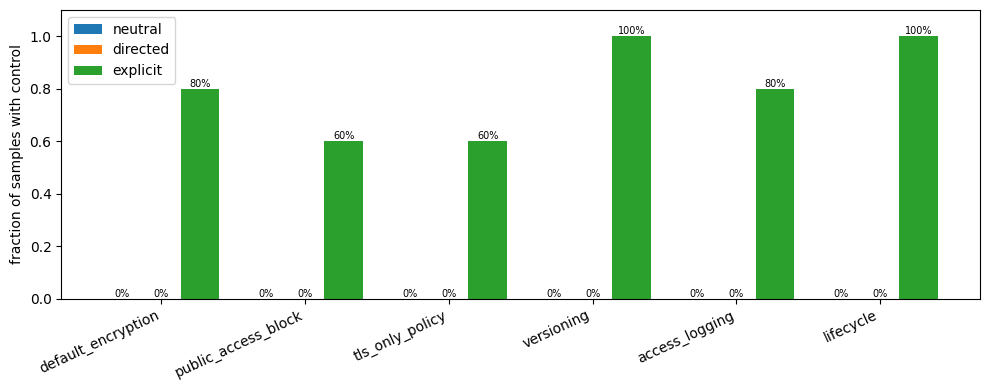

In [41]:
import matplotlib.pyplot as plt
ks, conds = list(STRICT), ["neutral", "directed", "explicit"]
x, w = np.arange(len(ks)), 0.27
plt.figure(figsize=(10, 4))
for j, c in enumerate(conds):
    v = [np.mean([score(r["code"], STRICT)[k] for r in results[c]]) for k in ks]
    plt.bar_label(plt.bar(x + (j-1)*w, v, w, label=c), fmt="%.0f%%" , labels=[f"{a:.0%}" for a in v], fontsize=7)
plt.xticks(x, ks, rotation=25, ha="right"); plt.ylim(0, 1.1)
plt.ylabel("fraction of samples with control"); plt.legend(); plt.tight_layout()
plt.savefig("/content/drive/MyDrive/soc2_chart3.png", dpi=150); plt.show()